# ELS Optimal Hedge

**Project:** ELS 최적헤지와 헤지운용  
**Underlying:** KOSPI200  
**Product Type:** Step-down ELS with knock-in  
**Notebook Scope:** Section 0 ~ Section 2

이 노트북은 다음 단계까지 구현합니다.

- Section 0. 프로젝트 기본 세팅
- Section 1. KOSPI200 데이터 불러오기 및 변동성 추정
- Section 2. Monte Carlo Simulation

폴더 구조는 아래와 같이 가정합니다.

```text
project/
│
├─ data/
│  └─ kospi200_close_data.csv
│
├─ output/
├─ figures/
│
└─ ELS_Optimal_Hedge/
   └─ ELS_Optimal_Hedge.ipynb
```

# Section 0. 프로젝트 기본 세팅

In [1]:
# ============================================================
# Section 0. Project Setting
# Project: ELS Optimal Hedge & Hedge Trading
# Underlying: KOSPI200
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from dataclasses import dataclass
from datetime import datetime

import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", "{:,.6f}".format)

## 0-1. 프로젝트 폴더 및 데이터 경로 설정

In [2]:
# ============================================================
# 0-1. Project Directory Setting
# ============================================================

PROJECT_NAME = "ELS hege 5.19"
CURRENT_DIR = Path.cwd()


def find_project_dir(project_name=PROJECT_NAME):
    """
    Resolve the local project folder from the notebook folder, a subfolder,
    or the parent workspace folder.
    """
    current = Path.cwd().resolve()

    if current.name == project_name:
        return current

    for parent in current.parents:
        if parent.name == project_name:
            return parent

    for base in [current, *current.parents]:
        candidate = base / project_name
        if candidate.exists():
            return candidate.resolve()

    return current / project_name


PROJECT_DIR = find_project_dir()

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "output"
FIGURE_DIR = PROJECT_DIR / "figures"
CODE_DIR = PROJECT_DIR

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

KOSPI200_PATH = DATA_DIR / "kospi200_close_new.csv"

print("CURRENT_DIR:", CURRENT_DIR)
print("PROJECT_DIR:", PROJECT_DIR)
print("DATA_DIR:", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)
print("FIGURE_DIR:", FIGURE_DIR)
print("CODE_DIR:", CODE_DIR)
print("KOSPI200_PATH:", KOSPI200_PATH)
print("Data file exists:", KOSPI200_PATH.exists())


CURRENT_DIR: c:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
PROJECT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
DATA_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data
OUTPUT_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output
FIGURE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\figures
CODE_DIR: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19
KOSPI200_PATH: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\data\kospi200_close_new.csv
Data file exists: True


## 0-2. 상품 기본 정보 설정

In [3]:
# ============================================================
# 0-2. ELS Product Specification
# ============================================================

@dataclass
class ELSProduct:
    underlying: str
    notional: float
    issue_date: str
    maturity_date: str
    payment_date: str
    annual_coupon: float
    maturity_years: float
    autocall_dates: list
    autocall_barriers: list
    knock_in_barrier: float
    max_loss_rate: float

els = ELSProduct(
    underlying="KOSPI200",
    notional=10_000_000_000,  # 100억원
    issue_date="2026-05-14",
    maturity_date="2029-05-09",
    payment_date="2029-05-14",
    annual_coupon=0.097,      # 연 9.70%
    maturity_years=3.0,
    autocall_dates=[
        "2026-11-10",
        "2027-05-10",
        "2027-11-09",
        "2028-05-09",
        "2028-11-09",
        "2029-05-09",
    ],
    autocall_barriers=[0.85, 0.85, 0.85, 0.80, 0.75, 0.70],
    knock_in_barrier=0.35,
    max_loss_rate=-1.00
)

els

ELSProduct(underlying='KOSPI200', notional=10000000000, issue_date='2026-05-14', maturity_date='2029-05-09', payment_date='2029-05-14', annual_coupon=0.097, maturity_years=3.0, autocall_dates=['2026-11-10', '2027-05-10', '2027-11-09', '2028-05-09', '2028-11-09', '2029-05-09'], autocall_barriers=[0.85, 0.85, 0.85, 0.8, 0.75, 0.7], knock_in_barrier=0.35, max_loss_rate=-1.0)

## 0-3. 원금북/헤지북 비중 및 정적/동적 헤지 grid

In [4]:
# ============================================================
# 0-3. Book Allocation & Hedge Strategy Setting
# ============================================================

NOTIONAL = els.notional
PRINCIPAL_DAILY_RATE = 0.03 / 365

# 문맥상 30%, 50%, 70%를 원금북 비중으로 둔다.
principal_book_ratios = [0.30, 0.50, 0.70]
hedge_book_ratios = [1 - x for x in principal_book_ratios]

book_allocation_df = pd.DataFrame({
    "principal_book_ratio": principal_book_ratios,
    "hedge_book_ratio": hedge_book_ratios,
    "principal_book_amount": [NOTIONAL * x for x in principal_book_ratios],
    "hedge_book_amount": [NOTIONAL * x for x in hedge_book_ratios],
})

display(book_allocation_df)

# 헤지북 내 정적헤지 비중 후보
static_hedge_ratios = np.arange(0.0, 1.01, 0.1)
dynamic_hedge_ratios = 1 - static_hedge_ratios

hedge_ratio_grid = pd.DataFrame({
    "static_ratio": static_hedge_ratios,
    "dynamic_ratio": dynamic_hedge_ratios
})

display(hedge_ratio_grid)

,principal_book_ratio,hedge_book_ratio,principal_book_amount,hedge_book_amount
0,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000"
1,0.500000,0.500000,"5,000,000,000.000000","5,000,000,000.000000"
2,0.700000,0.300000,"7,000,000,000.000000","3,000,000,000.000000"


,static_ratio,dynamic_ratio
0,0.000000,1.000000
1,0.100000,0.900000
2,0.200000,0.800000
3,0.300000,0.700000
4,0.400000,0.600000
5,0.500000,0.500000
6,0.600000,0.400000
7,0.700000,0.300000
8,0.800000,0.200000
9,0.900000,0.100000


## 0-4. 전체 실험 조합 만들기

In [5]:
# ============================================================
# 0-4. Full Experiment Grid
# ============================================================

experiment_list = []

for principal_ratio in principal_book_ratios:
    hedge_ratio = 1 - principal_ratio
    principal_amount = NOTIONAL * principal_ratio
    hedge_amount = NOTIONAL * hedge_ratio

    for static_ratio in static_hedge_ratios:
        dynamic_ratio = 1 - static_ratio
        static_budget = hedge_amount * static_ratio
        dynamic_budget = hedge_amount * dynamic_ratio

        experiment_list.append({
            "principal_book_ratio": principal_ratio,
            "hedge_book_ratio": hedge_ratio,
            "principal_book_amount": principal_amount,
            "hedge_book_amount": hedge_amount,
            "static_ratio": static_ratio,
            "dynamic_ratio": dynamic_ratio,
            "static_budget": static_budget,
            "dynamic_budget": dynamic_budget,
        })

experiment_grid = pd.DataFrame(experiment_list)

print("Number of experiments:", len(experiment_grid))
display(experiment_grid.head(15))
display(experiment_grid.tail())

Number of experiments: 33


,principal_book_ratio,hedge_book_ratio,principal_book_amount,hedge_book_amount,static_ratio,dynamic_ratio,static_budget,dynamic_budget
0,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.000000,1.000000,0.000000,"7,000,000,000.000000"
1,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.100000,0.900000,"700,000,000.000000","6,300,000,000.000000"
2,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.200000,0.800000,"1,400,000,000.000000","5,600,000,000.000000"
3,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.300000,0.700000,"2,100,000,000.000000","4,900,000,000.000000"
4,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.400000,0.600000,"2,800,000,000.000000","4,200,000,000.000000"
5,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.500000,0.500000,"3,500,000,000.000000","3,500,000,000.000000"
6,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.600000,0.400000,"4,200,000,000.000000","2,800,000,000.000000"
7,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.700000,0.300000,"4,900,000,000.000000","2,100,000,000.000000"
8,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.800000,0.200000,"5,600,000,000.000000","1,400,000,000.000000"
9,0.300000,0.700000,"3,000,000,000.000000","7,000,000,000.000000",0.900000,0.100000,"6,300,000,000.000000","700,000,000.000000"


,principal_book_ratio,hedge_book_ratio,principal_book_amount,hedge_book_amount,static_ratio,dynamic_ratio,static_budget,dynamic_budget
28,0.700000,0.300000,"7,000,000,000.000000","3,000,000,000.000000",0.600000,0.400000,"1,800,000,000.000000","1,200,000,000.000000"
29,0.700000,0.300000,"7,000,000,000.000000","3,000,000,000.000000",0.700000,0.300000,"2,100,000,000.000000","900,000,000.000000"
30,0.700000,0.300000,"7,000,000,000.000000","3,000,000,000.000000",0.800000,0.200000,"2,400,000,000.000000","600,000,000.000000"
31,0.700000,0.300000,"7,000,000,000.000000","3,000,000,000.000000",0.900000,0.100000,"2,700,000,000.000000","300,000,000.000000"
32,0.700000,0.300000,"7,000,000,000.000000","3,000,000,000.000000",1.000000,0.000000,"3,000,000,000.000000",0.000000


## 0-5. 프로젝트 핵심 가정 정리

In [6]:
# ============================================================
# 0-5. Modeling Assumptions
# ============================================================

assumptions = {
    "underlying": "KOSPI200",
    "product_type": "Step-down ELS with knock-in",
    "issuer_perspective": True,
    "notional": NOTIONAL,
    "principal_book_daily_growth": "1 + 0.03 / 365",
    "static_hedge": "Short vanilla put option",
    "dynamic_hedge": "FDM-based delta hedge with weekly rebalancing",
    "performance_metric": "Terminal balance / remaining account balance",
    "early_redemption_treatment": (
        "If early redemption occurs, payoff is settled and remaining balance is "
        "invested like principal book until final maturity for performance comparison."
    ),
    "hedge_constraint": "Static + dynamic hedge cost must not exceed allocated hedge book amount."
}

assumptions

{'underlying': 'KOSPI200',
 'product_type': 'Step-down ELS with knock-in',
 'issuer_perspective': True,
 'notional': 10000000000,
 'principal_book_daily_growth': '1 + 0.03 / 365',
 'static_hedge': 'Short vanilla put option',
 'dynamic_hedge': 'FDM-based delta hedge with weekly rebalancing',
 'performance_metric': 'Terminal balance / remaining account balance',
 'early_redemption_treatment': 'If early redemption occurs, payoff is settled and remaining balance is invested like principal book until final maturity for performance comparison.',
 'hedge_constraint': 'Static + dynamic hedge cost must not exceed allocated hedge book amount.'}

# Section 1. KOSPI200 데이터 불러오기 및 변동성 추정

## 1-1. KOSPI200 데이터 불러오기

In [7]:
# ============================================================
# Section 1. Load KOSPI200 Data & Estimate Volatility
# ============================================================

def read_csv_safely(path):
    """CSV 파일 인코딩 문제를 피하기 위한 함수"""
    encodings = ["utf-8-sig", "cp949", "euc-kr", "utf-8"]

    for enc in encodings:
        try:
            df = pd.read_csv(path, encoding=enc)
            print(f"Successfully loaded with encoding: {enc}")
            return df
        except UnicodeDecodeError:
            continue

    raise ValueError("Failed to read the CSV file with common encodings.")

kospi_raw = read_csv_safely(KOSPI200_PATH)

print("Shape:", kospi_raw.shape)
display(kospi_raw.head())
display(kospi_raw.tail())
print("Columns:", list(kospi_raw.columns))

Successfully loaded with encoding: utf-8-sig
Shape: (1563, 2)


,Date,KOSPI200
0,2020-01-02,290.350000
1,2020-01-03,290.740000
2,2020-01-06,288.430000
3,2020-01-07,291.230000
4,2020-01-08,289.420000


,Date,KOSPI200
1558,2026-05-11,"1,211.440000"
1559,2026-05-12,"1,183.410000"
1560,2026-05-13,"1,220.170000"
1561,2026-05-14,"1,243.170000"
1562,2026-05-15,"1,162.390000"


Columns: ['Date', 'KOSPI200']


## 1-2. 날짜 컬럼과 종가 컬럼 자동 탐색

In [8]:
# ============================================================
# 1-2. Detect Date Column and Close Price Column
# ============================================================

def detect_date_column(df):
    date_candidates = ["Date", "date", "날짜", "일자", "기준일", "거래일"]

    for col in df.columns:
        if col in date_candidates:
            return col

    return df.columns[0]


def detect_close_column(df):
    close_candidates = [
        "Close", "close", "Adj Close", "adj_close",
        "종가", "수정종가", "현재가", "KOSPI200", "코스피200"
    ]

    for col in df.columns:
        if col in close_candidates:
            return col

    numeric_like_cols = []

    for col in df.columns:
        temp = (
            df[col]
            .astype(str)
            .str.replace(",", "", regex=False)
            .str.replace(" ", "", regex=False)
        )
        converted = pd.to_numeric(temp, errors="coerce")

        if converted.notna().sum() > len(df) * 0.5:
            numeric_like_cols.append(col)

    if len(numeric_like_cols) == 0:
        raise ValueError("종가로 사용할 수 있는 숫자형 컬럼을 찾지 못했습니다.")

    return numeric_like_cols[-1]


date_col = detect_date_column(kospi_raw)
close_col = detect_close_column(kospi_raw)

print("Detected date column:", date_col)
print("Detected close column:", close_col)

Detected date column: Date
Detected close column: KOSPI200


## 1-3. 데이터 정리

In [9]:
# ============================================================
# 1-3. Clean KOSPI200 Close Data
# ============================================================

kospi = kospi_raw[[date_col, close_col]].copy()
kospi.columns = ["Date", "Close"]

kospi["Date"] = pd.to_datetime(kospi["Date"], errors="coerce")

kospi["Close"] = (
    kospi["Close"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(" ", "", regex=False)
)

kospi["Close"] = pd.to_numeric(kospi["Close"], errors="coerce")

kospi = kospi.dropna(subset=["Date", "Close"])
kospi = kospi.sort_values("Date").reset_index(drop=True)
kospi = kospi.set_index("Date")

# 분석 기간 제한
kospi = kospi.loc["2020-01-01":"2026-05-08"].copy()

display(kospi.head())
display(kospi.tail())

print("Start date:", kospi.index.min())
print("End date:", kospi.index.max())
print("Number of observations:", len(kospi))

,Close
Date,
2020-01-02,290.350000
2020-01-03,290.740000
2020-01-06,288.430000
2020-01-07,291.230000
2020-01-08,289.420000


,Close
Date,
2026-04-30,992.150000
2026-05-04,"1,049.660000"
2026-05-06,"1,129.630000"
2026-05-07,"1,149.860000"
2026-05-08,"1,151.170000"


Start date: 2020-01-02 00:00:00
End date: 2026-05-08 00:00:00
Number of observations: 1558


## 1-4. KOSPI200 가격 그래프 확인

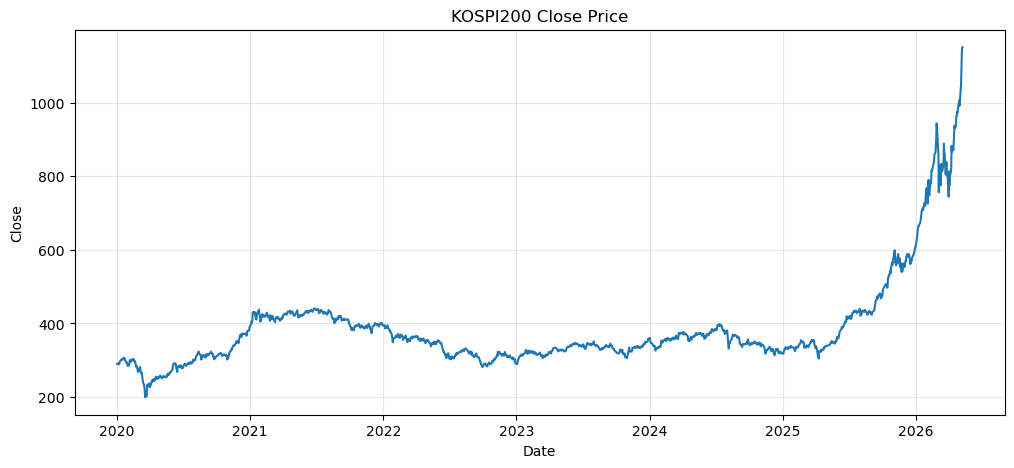

In [10]:
# ============================================================
# 1-4. Plot KOSPI200 Close Price
# ============================================================

plt.figure(figsize=(12, 5))
plt.plot(kospi.index, kospi["Close"])
plt.title("KOSPI200 Close Price")
plt.xlabel("Date")
plt.ylabel("Close")
plt.grid(True, alpha=0.3)
plt.show()

## 1-5. 수익률 및 Historical Volatility 추정

In [11]:
# ============================================================
# 1-5. Calculate Daily Returns and Historical Volatility
# ============================================================

kospi["simple_return"] = kospi["Close"].pct_change()
kospi["log_return"] = np.log(kospi["Close"] / kospi["Close"].shift(1))
kospi = kospi.dropna().copy()

display(kospi.head())

TRADING_DAYS = 252

daily_mu = kospi["log_return"].mean()
daily_sigma = kospi["log_return"].std(ddof=1)

annual_mu = daily_mu * TRADING_DAYS
annual_sigma = daily_sigma * np.sqrt(TRADING_DAYS)

print("Daily mean return:", daily_mu)
print("Daily volatility:", daily_sigma)
print("Annualized mean return:", annual_mu)
print("Annualized volatility:", annual_sigma)

,Close,simple_return,log_return
Date,,,
2020-01-03,290.740000,0.001343,0.001342
2020-01-06,288.430000,-0.007945,-0.007977
2020-01-07,291.230000,0.009708,0.009661
2020-01-08,289.420000,-0.006215,-0.006234
2020-01-09,294.410000,0.017241,0.017094


Daily mean return: 0.0008846801564879957
Daily volatility: 0.015582492543623374
Annualized mean return: 0.22293939943497493
Annualized volatility: 0.2473644004616745


## 1-6. 기간별 변동성 비교

In [12]:
# ============================================================
# 1-6. Compare Volatility by Estimation Window
# ============================================================

def estimate_annual_volatility(return_series):
    return return_series.std(ddof=1) * np.sqrt(TRADING_DAYS)

vol_full = estimate_annual_volatility(kospi["log_return"])
vol_1y = estimate_annual_volatility(kospi["log_return"].iloc[-TRADING_DAYS:])
vol_3y = estimate_annual_volatility(kospi["log_return"].iloc[-TRADING_DAYS * 3:])

vol_summary = pd.DataFrame({
    "window": ["Full sample", "Recent 1 year", "Recent 3 years"],
    "annualized_volatility": [vol_full, vol_1y, vol_3y]
})

vol_summary

,window,annualized_volatility
0,Full sample,0.247364
1,Recent 1 year,0.373737
2,Recent 3 years,0.272042


## 1-7. 프로젝트에서 사용할 변동성 선택

In [13]:
# ============================================================
# 1-7. Select Volatility for Simulation and Pricing
# ============================================================

SIGMA = vol_3y
RISK_FREE_RATE = 0.03
MU = RISK_FREE_RATE

print("Selected annual volatility SIGMA:", SIGMA)
print("Risk-free rate:", RISK_FREE_RATE)
print("Simulation drift MU:", MU)

Selected annual volatility SIGMA: 0.27204175491895777
Risk-free rate: 0.03
Simulation drift MU: 0.03


## 1-8. 정규화된 KOSPI200 가격 생성

,Close,simple_return,log_return,normalized_close
Date,,,,
2026-04-30,992.150000,-0.014345,-0.014449,86.186228
2026-05-04,"1,049.660000",0.057965,0.056347,91.182015
2026-05-06,"1,129.630000",0.076187,0.073424,98.128860
2026-05-07,"1,149.860000",0.017909,0.017750,99.886203
2026-05-08,"1,151.170000",0.001139,0.001139,100.000000


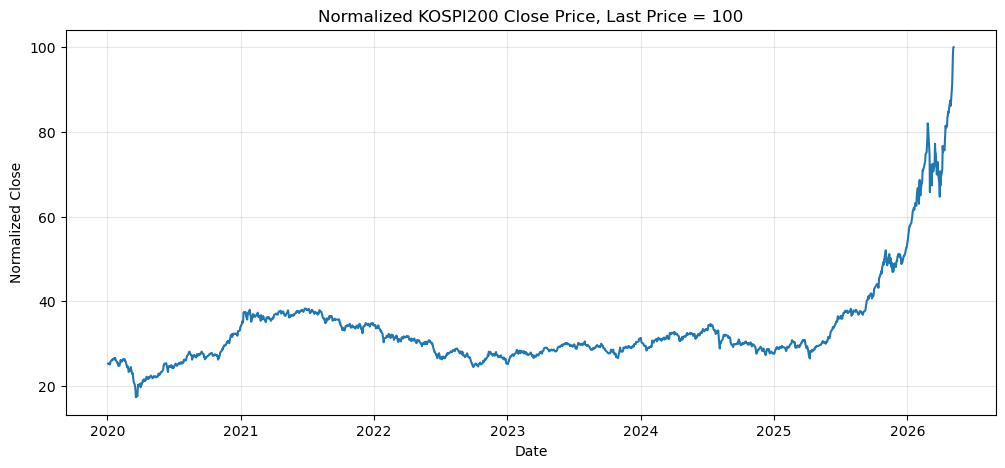

In [14]:
# ============================================================
# 1-8. Normalize KOSPI200 Index to S0 = 100
# ============================================================

kospi["normalized_close"] = kospi["Close"] / kospi["Close"].iloc[-1] * 100
S0 = 100

display(kospi.tail())

plt.figure(figsize=(12, 5))
plt.plot(kospi.index, kospi["normalized_close"])
plt.title("Normalized KOSPI200 Close Price, Last Price = 100")
plt.xlabel("Date")
plt.ylabel("Normalized Close")
plt.grid(True, alpha=0.3)
plt.show()

## 1-9. Section 1 결과 저장

In [15]:
# ============================================================
# 1-9. Save Cleaned Data and Parameters
# ============================================================

cleaned_data_path = OUTPUT_DIR / "kospi200_cleaned.csv"
kospi.to_csv(cleaned_data_path, encoding="utf-8-sig")

market_params = {
    "S0": S0,
    "MU": MU,
    "SIGMA": SIGMA,
    "RISK_FREE_RATE": RISK_FREE_RATE,
    "TRADING_DAYS": TRADING_DAYS,
    "vol_full": vol_full,
    "vol_1y": vol_1y,
    "vol_3y": vol_3y,
}

market_params_df = pd.DataFrame([market_params])
market_params_path = OUTPUT_DIR / "market_params.csv"
market_params_df.to_csv(market_params_path, index=False, encoding="utf-8-sig")

print("Saved cleaned data to:", cleaned_data_path)
print("Saved market parameters to:", market_params_path)

market_params_df

Saved cleaned data to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\kospi200_cleaned.csv
Saved market parameters to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\market_params.csv


,S0,MU,SIGMA,RISK_FREE_RATE,TRADING_DAYS,vol_full,vol_1y,vol_3y
0,100,0.030000,0.272042,0.030000,252,0.247364,0.373737,0.272042


# Section 2. Monte Carlo Simulation

## 2-1. 시뮬레이션 기본 설정

In [16]:
# ============================================================
# Section 2. Monte Carlo Simulation
# ============================================================

#N_PATHS = 10_000
#T = els.maturity_years
#DT = 1 / TRADING_DAYS
#N_STEPS = int(T * TRADING_DAYS)

#print("Number of paths:", N_PATHS)
#print("Number of time steps:", N_STEPS)
#print("dt:", DT)

## 2-2. 미래 영업일 캘린더 만들기

In [17]:
# ============================================================
# 2-2. Create Future Business Date Calendar
# ============================================================

#issue_date = pd.to_datetime(els.issue_date)
#maturity_date = pd.to_datetime(els.maturity_date)

# 한국 휴일은 단순화를 위해 제외하고 business day 기준으로 생성
#sim_dates = pd.bdate_range(start=issue_date, periods=N_STEPS + 1)

#print("Simulation start:", sim_dates[0])
#print("Simulation end:", sim_dates[-1])
#print("Target maturity date:", maturity_date)
#print("Number of simulation dates:", len(sim_dates))

In [18]:
# ============================================================
# 2-1. Simulation Calendar Setting - Corrected
# ============================================================

N_PATHS = 10_000

issue_date = pd.to_datetime(els.issue_date)
maturity_date = pd.to_datetime(els.maturity_date)

# 실제 발행일 ~ 만기평가일까지의 영업일 calendar 생성
sim_dates = pd.bdate_range(start=issue_date, end=maturity_date)

# time step은 calendar에 맞춰 다시 정의
N_STEPS = len(sim_dates) - 1

# 모형상 만기는 3년으로 유지
T = els.maturity_years
dt = T / N_STEPS

print("Number of paths:", N_PATHS)
print("Simulation start:", sim_dates[0])
print("Simulation end:", sim_dates[-1])
print("Target maturity date:", maturity_date)
print("Number of simulation dates:", len(sim_dates))
print("N_STEPS:", N_STEPS)
print("dt:", dt)

Number of paths: 10000
Simulation start: 2026-05-14 00:00:00
Simulation end: 2029-05-09 00:00:00
Target maturity date: 2029-05-09 00:00:00
Number of simulation dates: 780
N_STEPS: 779
dt: 0.0038510911424903724


## 2-3. 자동조기상환 평가일 index 매핑

In [19]:
# ============================================================
# 2-3. Map Autocall Dates to Simulation Indices - Corrected
# ============================================================

autocall_dates = pd.to_datetime(els.autocall_dates)

def get_nearest_sim_index(target_date, sim_dates):
    diff = np.abs(sim_dates - target_date)
    return int(np.argmin(diff))

autocall_indices = [
    get_nearest_sim_index(date, sim_dates)
    for date in autocall_dates
]

# coupon year fraction은 계약상 6개월 단위로 고정
coupon_year_fractions = np.array([0.5, 1.0, 1.5, 2.0, 2.5, 3.0])

autocall_schedule = pd.DataFrame({
    "autocall_no": np.arange(1, len(autocall_dates) + 1),
    "target_date": autocall_dates,
    "sim_date": [sim_dates[i] for i in autocall_indices],
    "time_index": autocall_indices,
    "year_fraction": coupon_year_fractions,
    "barrier": els.autocall_barriers
})

autocall_schedule

,autocall_no,target_date,sim_date,time_index,year_fraction,barrier
0,1,2026-11-10,2026-11-10,128,0.500000,0.850000
1,2,2027-05-10,2027-05-10,257,1.000000,0.850000
2,3,2027-11-09,2027-11-09,388,1.500000,0.850000
3,4,2028-05-09,2028-05-09,518,2.000000,0.800000
4,5,2028-11-09,2028-11-09,650,2.500000,0.750000
5,6,2029-05-09,2029-05-09,779,3.000000,0.700000


## 2-4. GBM 기반 KOSPI200 경로 생성

In [20]:
# ============================================================
# 2-4. Generate GBM Monte Carlo Paths
# ============================================================

def generate_gbm_paths(S0, mu, sigma, T, n_steps, n_paths, seed=42):
    """
    GBM 기반 Monte Carlo path 생성
    Returns: shape = (n_paths, n_steps + 1)
    """
    np.random.seed(seed)
    dt = T / n_steps
    Z = np.random.normal(size=(n_paths, n_steps))
    drift = (mu - 0.5 * sigma ** 2) * dt
    diffusion = sigma * np.sqrt(dt) * Z
    log_returns = drift + diffusion

    paths = np.zeros((n_paths, n_steps + 1))
    paths[:, 0] = S0
    paths[:, 1:] = S0 * np.exp(np.cumsum(log_returns, axis=1))

    return paths

paths = generate_gbm_paths(
    S0=S0,
    mu=MU,
    sigma=SIGMA,
    T=T,
    n_steps=N_STEPS,
    n_paths=N_PATHS,
    seed=SEED
)

print("paths shape:", paths.shape)
print("Initial price check:", paths[:, 0].mean())
print("Final price mean:", paths[:, -1].mean())

paths shape: (10000, 780)
Initial price check: 100.0
Final price mean: 109.0034584910162


## 2-5. 생성된 경로 일부 시각화

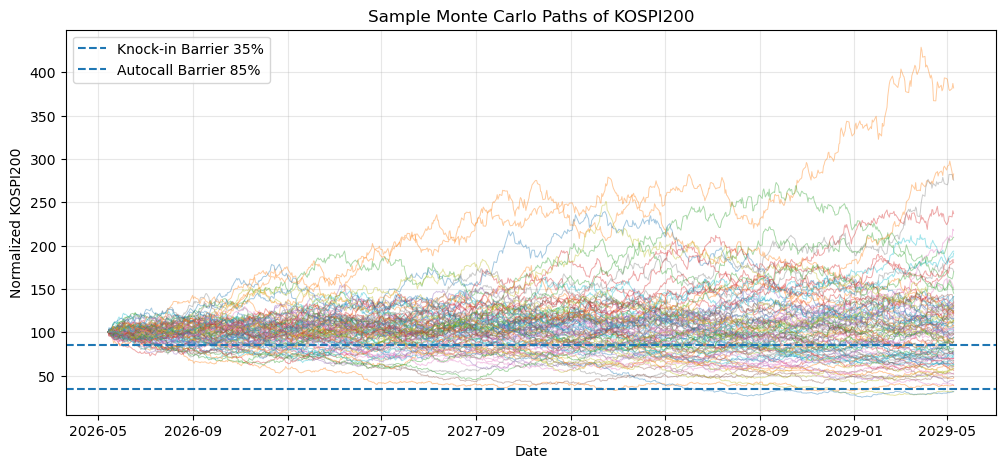

In [21]:
# ============================================================
# 2-5. Plot Sample Monte Carlo Paths
# ============================================================

plt.figure(figsize=(12, 5))

sample_n = 100
for i in range(sample_n):
    plt.plot(sim_dates, paths[i], linewidth=0.7, alpha=0.4)

plt.axhline(S0 * els.knock_in_barrier, linestyle="--", label="Knock-in Barrier 35%")
plt.axhline(S0 * 0.85, linestyle="--", label="Autocall Barrier 85%")
plt.title("Sample Monte Carlo Paths of KOSPI200")
plt.xlabel("Date")
plt.ylabel("Normalized KOSPI200")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 2-6. 경로 요약 통계 및 knock-in 확인

In [22]:
# ============================================================
# 2-6. Path Summary Statistics and Knock-in Event
# ============================================================

final_prices = paths[:, -1]
min_prices = paths.min(axis=1)
max_prices = paths.max(axis=1)

path_summary = pd.DataFrame({
    "final_price": final_prices,
    "min_price": min_prices,
    "max_price": max_prices
})

display(path_summary.describe())

ki_level = S0 * els.knock_in_barrier
knock_in_occurred = paths.min(axis=1) <= ki_level

ki_summary = pd.Series(knock_in_occurred).value_counts(normalize=True).rename({
    False: "No Knock-in",
    True: "Knock-in"
})

display(ki_summary)
print("Knock-in probability:", knock_in_occurred.mean())
print("No knock-in probability:", 1 - knock_in_occurred.mean())

,final_price,min_price,max_price
count,"10,000.000000","10,000.000000","10,000.000000"
mean,109.003458,71.498062,148.553705
std,53.392586,18.094409,48.280158
min,17.820287,16.017709,100.000000
25%,72.080913,58.439629,114.956882
50%,98.728658,73.200505,134.783222
75%,133.714638,86.188861,167.008528
max,595.348242,100.000000,633.443627


No Knock-in   0.973600
Knock-in      0.026400
Name: proportion, dtype: float64

Knock-in probability: 0.0264
No knock-in probability: 0.9736


## 2-7. 자동조기상환 barrier 충족 여부 확인

In [23]:
# ============================================================
# 2-7. Check Autocall Condition by Observation Date
# ============================================================

autocall_check = pd.DataFrame(index=np.arange(N_PATHS))

for i, row in autocall_schedule.iterrows():
    obs_no = int(row["autocall_no"])
    obs_idx = int(row["time_index"])
    barrier = float(row["barrier"]) * S0

    autocall_check[f"obs_{obs_no}_price"] = paths[:, obs_idx]
    autocall_check[f"obs_{obs_no}_hit"] = paths[:, obs_idx] >= barrier

display(autocall_check.head())

autocall_hit_rates = []

for i, row in autocall_schedule.iterrows():
    obs_no = int(row["autocall_no"])
    hit_rate = autocall_check[f"obs_{obs_no}_hit"].mean()

    autocall_hit_rates.append({
        "autocall_no": obs_no,
        "barrier": row["barrier"],
        "sim_date": row["sim_date"],
        "hit_rate": hit_rate
    })

autocall_hit_rates = pd.DataFrame(autocall_hit_rates)
autocall_hit_rates

,obs_1_price,obs_1_hit,obs_2_price,obs_2_hit,obs_3_price,obs_3_hit,obs_4_price,obs_4_hit,obs_5_price,obs_5_hit,obs_6_price,obs_6_hit
0,86.483610,True,101.803212,True,111.498401,True,99.984055,True,88.040610,True,85.148390,True
1,151.946806,True,196.684353,True,261.052942,True,265.221439,True,279.073721,True,382.028553,True
2,112.761641,True,122.202456,True,116.219143,True,116.844238,True,110.650016,True,130.545363,True
3,85.336922,True,99.869105,True,120.546002,True,120.630980,True,106.802440,True,88.593817,True
4,88.157058,True,96.878188,True,105.740400,True,117.068091,True,131.155196,True,73.937730,True


,autocall_no,barrier,sim_date,hit_rate
0,1,0.850000,2026-11-10,0.803800
1,2,0.850000,2027-05-10,0.727700
2,3,0.850000,2027-11-09,0.688800
3,4,0.800000,2028-05-09,0.716800
4,5,0.750000,2028-11-09,0.739400
5,6,0.700000,2029-05-09,0.768800


## 2-8. 최초 조기상환 발생 시점 계산

In [24]:
# ============================================================
# 2-8. Find First Autocall Date for Each Path
# ============================================================

def find_first_autocall(paths, autocall_schedule, S0):
    """각 path별 최초 조기상환 발생 여부와 발생 회차를 계산"""
    n_paths = paths.shape[0]

    autocall_occurred = np.zeros(n_paths, dtype=bool)
    autocall_no = np.zeros(n_paths, dtype=int)
    autocall_index = np.full(n_paths, -1, dtype=int)

    for _, row in autocall_schedule.iterrows():
        obs_no = int(row["autocall_no"])
        obs_idx = int(row["time_index"])
        barrier_level = float(row["barrier"]) * S0

        not_yet_called = ~autocall_occurred
        hit = paths[:, obs_idx] >= barrier_level
        newly_called = not_yet_called & hit

        autocall_occurred[newly_called] = True
        autocall_no[newly_called] = obs_no
        autocall_index[newly_called] = obs_idx

    return autocall_occurred, autocall_no, autocall_index

autocall_occurred, autocall_no, autocall_index = find_first_autocall(
    paths=paths,
    autocall_schedule=autocall_schedule,
    S0=S0
)

print("Autocall probability:", autocall_occurred.mean())
print("No autocall probability:", 1 - autocall_occurred.mean())

Autocall probability: 0.9412
No autocall probability: 0.05879999999999996


## 2-9. 조기상환 회차별 분포

,autocall_no,count,probability
0,0,588,0.058800
1,1,8038,0.803800
2,2,607,0.060700
3,3,272,0.027200
4,4,202,0.020200
5,5,164,0.016400
6,6,129,0.012900


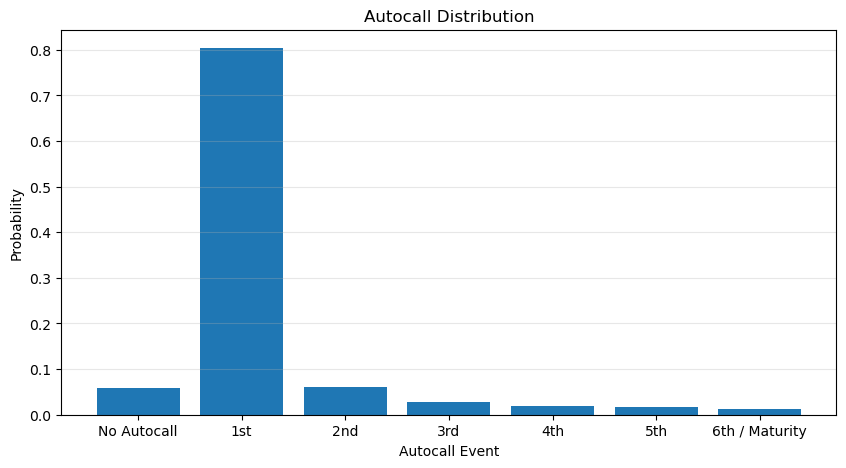

In [25]:
# ============================================================
# 2-9. Autocall Distribution
# ============================================================

autocall_result = pd.DataFrame({
    "autocall_occurred": autocall_occurred,
    "autocall_no": autocall_no,
    "autocall_index": autocall_index,
    "knock_in_occurred": knock_in_occurred,
    "final_price": final_prices,
    "min_price": min_prices
})

autocall_distribution = (
    autocall_result["autocall_no"]
    .value_counts()
    .sort_index()
    .rename_axis("autocall_no")
    .reset_index(name="count")
)

autocall_distribution["probability"] = autocall_distribution["count"] / N_PATHS

display(autocall_distribution)

plot_df = autocall_distribution.copy()
plot_df["label"] = plot_df["autocall_no"].replace({
    0: "No Autocall",
    1: "1st",
    2: "2nd",
    3: "3rd",
    4: "4th",
    5: "5th",
    6: "6th / Maturity"
})

plt.figure(figsize=(10, 5))
plt.bar(plot_df["label"], plot_df["probability"])
plt.title("Autocall Distribution")
plt.xlabel("Autocall Event")
plt.ylabel("Probability")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

## 2-10. Monte Carlo 결과 저장

In [26]:
# ============================================================
# 2-10. Save Monte Carlo Results
# ============================================================

paths_path = OUTPUT_DIR / "mc_paths.npy"
sim_dates_path = OUTPUT_DIR / "sim_dates.csv"
autocall_result_path = OUTPUT_DIR / "autocall_result.csv"
autocall_schedule_path = OUTPUT_DIR / "autocall_schedule.csv"
experiment_grid_path = OUTPUT_DIR / "experiment_grid.csv"
book_allocation_path = OUTPUT_DIR / "book_allocation.csv"

np.save(paths_path, paths)

pd.DataFrame({"Date": sim_dates}).to_csv(
    sim_dates_path,
    index=False,
    encoding="utf-8-sig"
)

autocall_result.to_csv(
    autocall_result_path,
    index=False,
    encoding="utf-8-sig"
)

autocall_schedule.to_csv(
    autocall_schedule_path,
    index=False,
    encoding="utf-8-sig"
)

experiment_grid.to_csv(
    experiment_grid_path,
    index=False,
    encoding="utf-8-sig"
)

book_allocation_df.to_csv(
    book_allocation_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved paths to:", paths_path)
print("Saved simulation dates to:", sim_dates_path)
print("Saved autocall result to:", autocall_result_path)
print("Saved autocall schedule to:", autocall_schedule_path)
print("Saved experiment grid to:", experiment_grid_path)
print("Saved book allocation to:", book_allocation_path)

Saved paths to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\mc_paths.npy
Saved simulation dates to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\sim_dates.csv
Saved autocall result to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\autocall_result.csv
Saved autocall schedule to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\autocall_schedule.csv
Saved experiment grid to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\experiment_grid.csv
Saved book allocation to: C:\Users\Yeonsoo\Desktop\project\ELS hege 5.19\output\book_allocation.csv


# Next Step

이 노트북은 Section 0~2까지만 담당합니다.

다음 파일은 아래와 같이 진행합니다.

```text
section_3_payoff.ipynb       # ELS payoff 계산
section_4_fdm_delta.ipynb    # FDM 가격 및 delta 계산
section_5_static_hedge.ipynb # 풋옵션 매도 정적헤지
section_6_dynamic_hedge.ipynb
section_7_grid_search.ipynb
section_8_result_analysis.ipynb
```